In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"

df = pd.concat([
    pd.read_excel(DATA_PATH, sheet_name="Year 2009-2010"),
    pd.read_excel(DATA_PATH, sheet_name="Year 2010-2011")
], ignore_index=True)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Unique customers:", df["Customer ID"].nunique())

Dataset shape: (1067371, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
Unique customers: 5942


In [2]:
# Convert dates and remove records without customer ID
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

customer_df = df.dropna(
    subset=["Customer ID", "InvoiceDate"]
).copy()

# Remove cancellations, negative quantities, and invalid prices
customer_df["Invoice"] = customer_df["Invoice"].astype(str)

customer_df = customer_df[
    (~customer_df["Invoice"].str.startswith("C")) &
    (customer_df["Quantity"] > 0) &
    (customer_df["Price"] > 0)
].copy()

# Calculate revenue
customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["Price"]
)

print("Clean data shape:", customer_df.shape)
print("Unique customers:", customer_df["Customer ID"].nunique())
print("Missing values:", customer_df[
    ["Customer ID", "InvoiceDate", "Quantity", "Price"]
].isnull().sum().sum())

print(customer_df.head())

Clean data shape: (805549, 9)
Unique customers: 5878
Missing values: 0
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  Revenue  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom     83.4  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom     81.0  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom    100.8  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom     30.0  


In [3]:
# Reference date: day after the last transaction
reference_date = customer_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

# Create customer-level features
customer_features = customer_df.groupby("Customer ID").agg(
    Last_Purchase=("InvoiceDate", "max"),
    Total_Orders=("Invoice", "nunique"),
    Total_Spending=("Revenue", "sum"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

# Calculate days since last purchase
customer_features["Recency_Days"] = (
    reference_date - customer_features["Last_Purchase"]
).dt.days

# Create a simple churn label:
# 1 = no purchase in the last 90 days
# 0 = purchased within the last 90 days
customer_features["Churn"] = (
    customer_features["Recency_Days"] > 90
).astype(int)

print("Customer-level dataset:", customer_features.shape)
print("\nChurn distribution:")
print(customer_features["Churn"].value_counts())
print("\nChurn percentage:")
print((customer_features["Churn"].value_counts(normalize=True) * 100).round(2))
print("\nSample records:")
print(customer_features.head())

Customer-level dataset: (5878, 7)

Churn distribution:
Churn
1    2989
0    2889
Name: count, dtype: int64

Churn percentage:
Churn
1    50.85
0    49.15
Name: proportion, dtype: float64

Sample records:
   Customer ID       Last_Purchase  Total_Orders  Total_Spending  \
0      12346.0 2011-01-18 10:01:00            12        77556.46   
1      12347.0 2011-12-07 15:52:00             8         5633.32   
2      12348.0 2011-09-25 13:13:00             5         2019.40   
3      12349.0 2011-11-21 09:51:00             4         4428.69   
4      12350.0 2011-02-02 16:01:00             1          334.40   

   Total_Quantity  Recency_Days  Churn  
0           74285           325      1  
1            3286             2      0  
2            2714            75      0  
3            1624            18      0  
4             197           310      1  


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# Input features
features = [
    "Total_Orders",
    "Total_Spending",
    "Total_Quantity",
    "Recency_Days"
]

X = customer_features[features]
y = customer_features["Churn"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train model
churn_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

churn_model.fit(X_train, y_train)

# Predict
y_pred = churn_model.predict(X_test)
y_prob = churn_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 1.0
ROC-AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       578
           1       1.00      1.00      1.00       598

    accuracy                           1.00      1176
   macro avg       1.00      1.00      1.00      1176
weighted avg       1.00      1.00      1.00      1176



In [5]:
# Remove the feature directly used to create the churn label
features = [
    "Total_Orders",
    "Total_Spending",
    "Total_Quantity"
]

X = customer_features[features]
y = customer_features["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

churn_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

churn_model.fit(X_train, y_train)

y_pred = churn_model.predict(X_test)
y_prob = churn_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6752
ROC-AUC: 0.7279

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.69      0.68       578
           1       0.69      0.66      0.67       598

    accuracy                           0.68      1176
   macro avg       0.68      0.68      0.68      1176
weighted avg       0.68      0.68      0.68      1176



In [6]:
import joblib
import json
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score
)

PROJECT_ROOT = Path.cwd().parent

MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(
    churn_model,
    MODEL_DIR / "churn_model.pkl"
)

# Save customer features and labels
customer_features.to_csv(
    PROCESSED_DIR / "customer_churn_data.csv",
    index=False
)

# Save evaluation metrics
metrics = {
    "model": "RandomForestClassifier",
    "accuracy": round(accuracy_score(y_test, y_pred), 4),
    "roc_auc": round(roc_auc_score(y_test, y_prob), 4),
    "precision_churn": round(
        precision_score(y_test, y_pred, pos_label=1), 4
    ),
    "churn_label_rule": "Churn=1 if Recency_Days > 90",
    "features": features
}

with open(REPORT_DIR / "churn_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Model saved:", (MODEL_DIR / "churn_model.pkl").exists())
print("Customer data saved:", (PROCESSED_DIR / "customer_churn_data.csv").exists())
print("Metrics saved:", (REPORT_DIR / "churn_metrics.json").exists())
print(json.dumps(metrics, indent=4))

Model saved: True
Customer data saved: True
Metrics saved: True
{
    "model": "RandomForestClassifier",
    "accuracy": 0.6752,
    "roc_auc": 0.7279,
    "precision_churn": 0.6875,
    "churn_label_rule": "Churn=1 if Recency_Days > 90",
    "features": [
        "Total_Orders",
        "Total_Spending",
        "Total_Quantity"
    ]
}


In [9]:
import importlib
import src.churn.churn_model as churn_module

importlib.reload(churn_module)

print("Function available:", hasattr(churn_module, "predict_churn"))

Function available: True


In [10]:
sample_customers = customer_features[
    ["Customer ID", "Total_Orders", "Total_Spending", "Total_Quantity"]
].head(5)

predictions = churn_module.predict_churn(sample_customers)

print(predictions[
    ["Customer ID", "Churn_Risk_Score", "Predicted_Churn"]
])

   Customer ID  Churn_Risk_Score  Predicted_Churn
0      12346.0             0.280                0
1      12347.0             0.035                0
2      12348.0             0.455                0
3      12349.0             0.205                0
4      12350.0             0.960                1


          Feature  Importance
1  Total_Spending    0.454064
2  Total_Quantity    0.410760
0    Total_Orders    0.135176


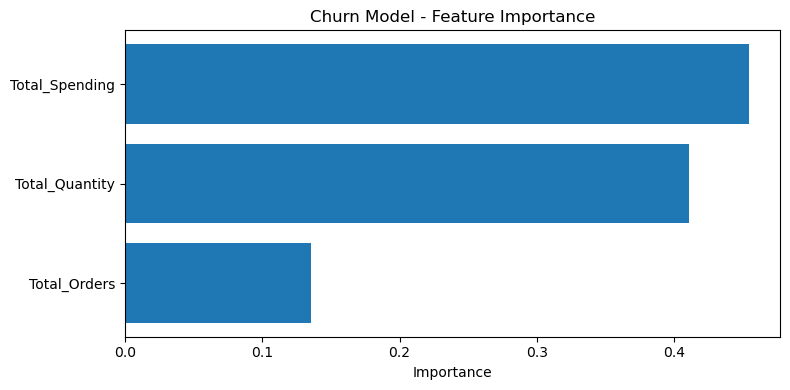

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": churn_module.load_model().feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df)

importance_df.to_csv(
    PROJECT_ROOT / "reports" / "churn_feature_importance.csv",
    index=False
)

plt.figure(figsize=(8, 4))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Importance")
plt.title("Churn Model - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [12]:
from pathlib import Path
import pandas as pd
import json

PROJECT_ROOT = Path.cwd().parent

files_to_check = [
    PROJECT_ROOT / "src" / "churn" / "churn_model.py",
    PROJECT_ROOT / "models" / "churn_model.pkl",
    PROJECT_ROOT / "data" / "processed" / "customer_churn_data.csv",
    PROJECT_ROOT / "reports" / "churn_metrics.json",
    PROJECT_ROOT / "reports" / "churn_feature_importance.csv",
]

for file_path in files_to_check:
    print(
        "OK" if file_path.exists() else "MISSING",
        file_path.relative_to(PROJECT_ROOT)
    )

print("\nFeature importance report:")
print(pd.read_csv(
    PROJECT_ROOT / "reports" / "churn_feature_importance.csv"
))

with open(PROJECT_ROOT / "reports" / "churn_metrics.json") as f:
    print("\nModel metrics:")
    print(json.load(f))

OK src\churn\churn_model.py
OK models\churn_model.pkl
OK data\processed\customer_churn_data.csv
OK reports\churn_metrics.json
OK reports\churn_feature_importance.csv

Feature importance report:
          Feature  Importance
0  Total_Spending    0.454064
1  Total_Quantity    0.410760
2    Total_Orders    0.135176

Model metrics:
{'model': 'RandomForestClassifier', 'accuracy': 0.6752, 'roc_auc': 0.7279, 'precision_churn': 0.6875, 'churn_label_rule': 'Churn=1 if Recency_Days > 90', 'features': ['Total_Orders', 'Total_Spending', 'Total_Quantity']}
